# 03 · Accesibilidad y cobertura: ¿quién queda lejos del cable?

**Pregunta:** ¿qué porcentaje de la población de La Paz y El Alto vive a 5, 10, 15 y 20 minutos a pie
de una estación de Mi Teleférico, cuánto se equivoca un buffer en línea recta y quién queda afuera?

**Datos y método** (`teleferico.access`, `teleferico.equidad`; tiempos por arista del notebook 02):
- **Origen:** los 32.860 manzanos del Censo 2024 (1,64 M de personas). Cada manzano toma su nodo de red
  más cercano y suma la caminata recta hasta él.
- **Destino:** las 26 estaciones físicas. Las "puertas" son los nodos a ≤ 75 m de cada estación.
- **Tiempo de la casa a la estación** (Dijkstra multi-origen sobre el grafo invertido), en tres variantes:
  1. **Euclidiano:** distancia en línea recta a velocidad plana (equivale a un buffer de 420/840/1.260/1.680 m).
  2. **Plana:** por la red de calles, sin pendiente (5,04 km/h).
  3. **Pendiente:** por la red, con Tobler direccional y perfil cada 30 m (la variante de referencia).
- "Cubierto" = a ≤ 15 minutos con pendiente.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

from teleferico import access as ac
from teleferico import demanda
from teleferico import equidad as eqm
from teleferico import viz
from teleferico.config import CRS_METRIC, CRS_WGS84, PROCESSED

viz.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

D = PROCESSED / "accesibilidad"
acc = pd.read_parquet(D / "manzanos_acceso.parquet")
cap = pd.read_parquet(D / "estaciones_captacion.parquet")
iso = gpd.read_parquet(D / "isocronas.parquet").to_crs(CRS_METRIC)
hx = pd.read_parquet(D / "h3_acceso_r9.parquet")
hx = gpd.GeoDataFrame(hx, geometry=ac.hexagonos(hx["h3"]).values, crs=CRS_WGS84).to_crs(CRS_METRIC)

lim = gpd.read_parquet(PROCESSED / "limites.parquet").to_crs(CRS_METRIC)
mun = lim.query("nivel == 'municipio'")
est = gpd.read_parquet(PROCESSED / "red" / "estaciones.parquet").to_crs(CRS_METRIC)
lineas = gpd.read_parquet(PROCESSED / "red" / "lineas.parquet").to_crs(CRS_METRIC)
bounds = hx.total_bounds + np.array([-500, -500, 500, 500])

eq = eqm.indicadores(acc)
kpi = ac.kpis(acc, eq)
ESC = {"euclidiano": "Euclidiano (línea recta)", "plana": "Red sin pendiente", "pendiente": "Red con pendiente"}
COL_ESC = {"euclidiano": viz.TINTA_3, "plana": viz.SECUENCIAL[2], "pendiente": viz.SECUENCIAL[5]}
pd.Series(kpi)

poblacion                         1,635,435.0
umbral_min                               15.0
pct_15min_euclidiano                     38.5
pct_15min_plana                          29.7
pct_15min_pendiente                      24.9
pct_15min_pendiente_la_paz               39.1
pct_15min_pendiente_el_alto              12.9
pct_15min_plana_la_paz                   49.5
pct_15min_plana_el_alto                  13.0
pob_no_cubierta_15min             1,227,666.0
pct_no_cubierta                          75.1
sobreestimacion_euclid_personas     221,439.0
sobreestimacion_plana_personas       78,432.0
pct_buffer_500m                          12.9
mediana_min_pendiente                    31.3
pct_15min_q1                             44.3
pct_15min_q5                              6.0
pob_vulnerable_no_cubierta          546,462.0
dtype: float64

## 1. El mapa: minutos a pie hasta la estación más cercana

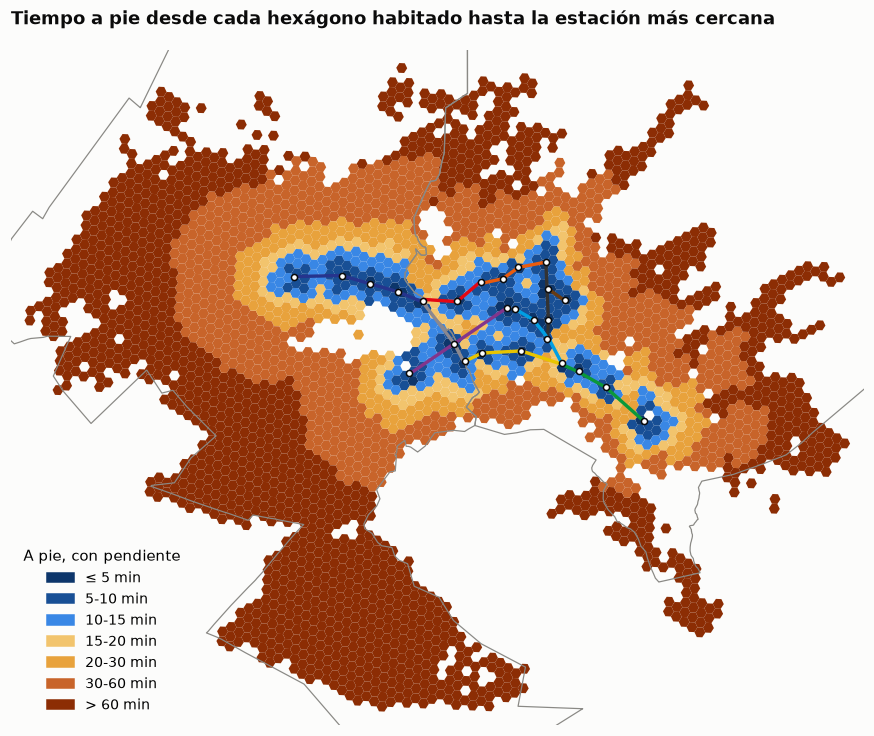

In [2]:
cortes = [0, 5, 10, 15, 20, 30, 60, np.inf]
etiquetas = ["≤ 5", "5-10", "10-15", "15-20", "20-30", "30-60", "> 60"]
colores = [viz.SECUENCIAL[6], viz.SECUENCIAL[5], viz.SECUENCIAL[3], "#f2c46d", "#e8a23c", "#c8642a", "#8c2d04"]
cmap, norm = ListedColormap(colores), BoundaryNorm(cortes[:-1] + [1e9], len(colores))

fig, ax = plt.subplots(figsize=(10, 8.5))
hx.plot(ax=ax, column=hx["t_pendiente_min"].clip(upper=1e8), cmap=cmap, norm=norm, linewidth=0)
viz.mapa_base(ax, mun, lineas, est, bounds)
ax.legend(handles=[Patch(color=c, label=f"{e} min") for c, e in zip(colores, etiquetas)],
          title="A pie, con pendiente", loc="lower left", fontsize=9)
ax.set_title("Tiempo a pie desde cada hexágono habitado hasta la estación más cercana")
viz.guardar(fig, "03_mapa_tiempo")
plt.show()

**Lectura:**
- La red forma un **corredor angosto**: el eje este-oeste de El Alto (línea Azul hasta Río Seco), la
  bajada por la Ceja y el valle central de La Paz hasta Irpavi. A ~1,5 km del cable el tiempo ya supera
  los 20-30 minutos.
- La mitad de la población vive a **más de 31 minutos a pie** de una estación (mediana ponderada).
- Las grandes manchas sin acceso a pie son el norte y el oeste de El Alto, el sur de El Alto y, en La
  Paz, la zona Sur más allá de Irpavi y las laderas altas del norte y del este.

## 2. Cobertura por banda de tiempo

In [3]:
tabla = pd.concat([ac.cobertura(acc), ac.cobertura(acc, "municipio")])
tabla = tabla[tabla["escenario"] == "pendiente"].set_index("grupo").drop(columns="escenario")
tabla["no_cubierta_15"] = tabla["poblacion"] * (100 - tabla["pct_15"]) / 100
tabla.style.format({"poblacion": viz.fmt_int, "no_cubierta_15": viz.fmt_int} |
                   {f"pct_{b}": "{:.1f} %" for b in ac.BANDAS_MIN})

,poblacion,pct_5,pct_10,pct_15,pct_20,no_cubierta_15
grupo,,,,,,
Total,1.635.435,3.1 %,13.1 %,24.9 %,33.8 %,1.227.666
El Alto,885.210,1.2 %,6.3 %,12.9 %,19.6 %,770.780
La Paz,750.225,5.4 %,21.3 %,39.1 %,50.7 %,456.886


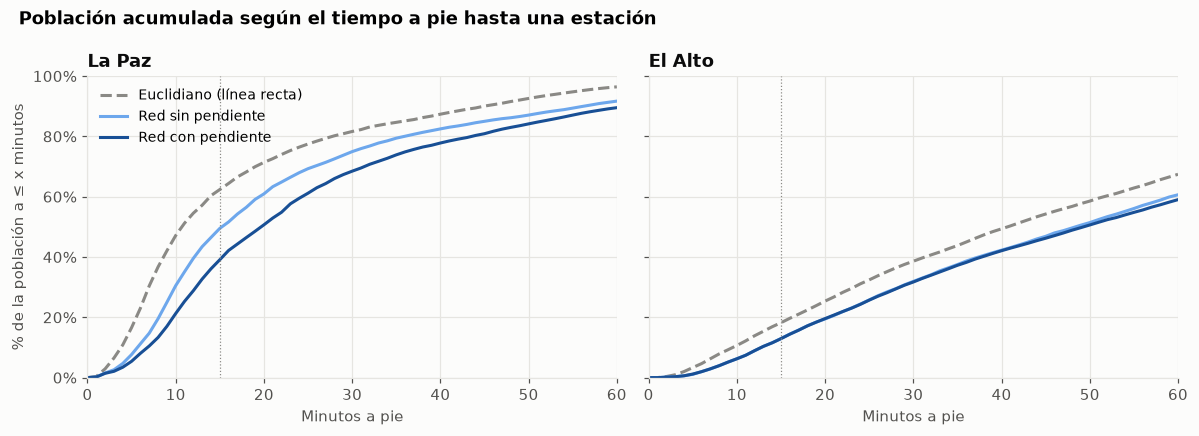

In [4]:
curvas = pd.concat([ac.curva_cobertura(acc, v, por="municipio").assign(escenario=v) for v in ESC])
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, m in zip(axs, ["La Paz", "El Alto"]):
    for v, nombre in ESC.items():
        c = curvas[(curvas["grupo"] == m) & (curvas["escenario"] == v)]
        ax.plot(c["minutos"], c["pct"], color=COL_ESC[v], label=nombre,
                ls="--" if v == "euclidiano" else "-")
    ax.axvline(15, color=viz.TINTA_3, lw=0.8, ls=":")
    ax.set_title(m)
    ax.set_xlabel("Minutos a pie")
    ax.set_xlim(0, 60)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
axs[0].set_ylabel("% de la población a ≤ x minutos")
axs[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Población acumulada según el tiempo a pie hasta una estación", x=0.02, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
viz.guardar(fig, "03_curvas_cobertura")
plt.show()

**Lectura:**
- Solo **1 de cada 4 personas (24,9 %, ~408 mil)** vive a 15 minutos o menos de una estación. **1,23 M de
  personas quedan afuera.**
- La brecha entre municipios es enorme: **El Alto, 12,9 %**, frente a **La Paz, 39,1 %**. Más de 770 mil
  alteños (87 %) viven a más de 15 minutos.
- En El Alto las tres curvas casi coinciden en la red: el altiplano es plano y la pendiente no cambia
  nada. En La Paz las curvas se separan: la pendiente desplaza toda la distribución hacia la derecha.

## 3. Hipótesis 1: la línea recta sobreestima la cobertura

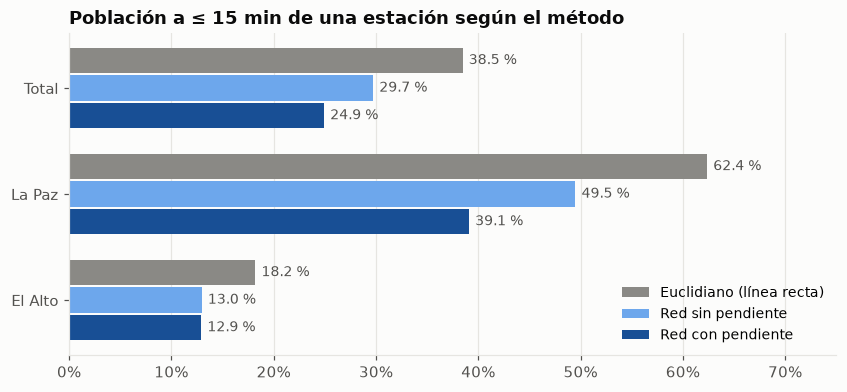

,% euclidiano,% plana,% pendiente,personas sobreestimadas (euclid. − pend.),personas sobreestimadas (plana − pend.),sobreestimación relativa euclid. (%)
grupo,,,,,,
Total,38.5,29.7,24.9,221.439,78.432,54.3
La Paz,62.4,49.5,39.1,174.637,78.031,59.5
El Alto,18.2,13.0,12.9,46.802,401,40.9


In [5]:
comp = pd.concat([ac.cobertura(acc), ac.cobertura(acc, "municipio")])
pivot = comp.pivot(index="grupo", columns="escenario", values="pct_15")[list(ESC)].loc[["Total", "La Paz", "El Alto"]]

fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(pivot))
for i, v in enumerate(ESC):
    ax.barh(y + (i - 1) * 0.26, pivot[v], height=0.24, color=COL_ESC[v], label=ESC[v])
    for yy, val in zip(y, pivot[v]):
        ax.text(val + 0.6, yy + (i - 1) * 0.26, f"{val:.1f} %", va="center", fontsize=9, color=viz.TINTA_2)
ax.set_yticks(y, pivot.index)
ax.invert_yaxis()
ax.set_xlim(0, 75)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.legend(loc="lower right", fontsize=9)
ax.set_title("Población a ≤ 15 min de una estación según el método")
viz.guardar(fig, "03_hipotesis_1")
plt.show()

pob = comp.drop_duplicates("grupo").set_index("grupo")["poblacion"]
personas = pivot.mul(pob.loc[pivot.index], axis=0) / 100
pd.DataFrame({
    "% euclidiano": pivot["euclidiano"], "% plana": pivot["plana"], "% pendiente": pivot["pendiente"],
    "personas sobreestimadas (euclid. − pend.)": personas["euclidiano"] - personas["pendiente"],
    "personas sobreestimadas (plana − pend.)": personas["plana"] - personas["pendiente"],
    "sobreestimación relativa euclid. (%)": (pivot["euclidiano"] / pivot["pendiente"] - 1) * 100,
}).style.format("{:,.1f}").format(viz.fmt_int, subset=pd.IndexSlice[:, ["personas sobreestimadas (euclid. − pend.)",
                                                                        "personas sobreestimadas (plana − pend.)"]])

El clásico **buffer de 500 m** alrededor de cada estación (≈ 6 minutos en llano) contiene al
12,9 % de la población. Equivale a medir solo la cobertura "inmediata".

### Dónde se equivoca más la línea recta

Isócronas de 15 minutos en el centro de La Paz: el círculo de 1.260 m (15 min en línea recta), la red sin
pendiente y la red con pendiente.

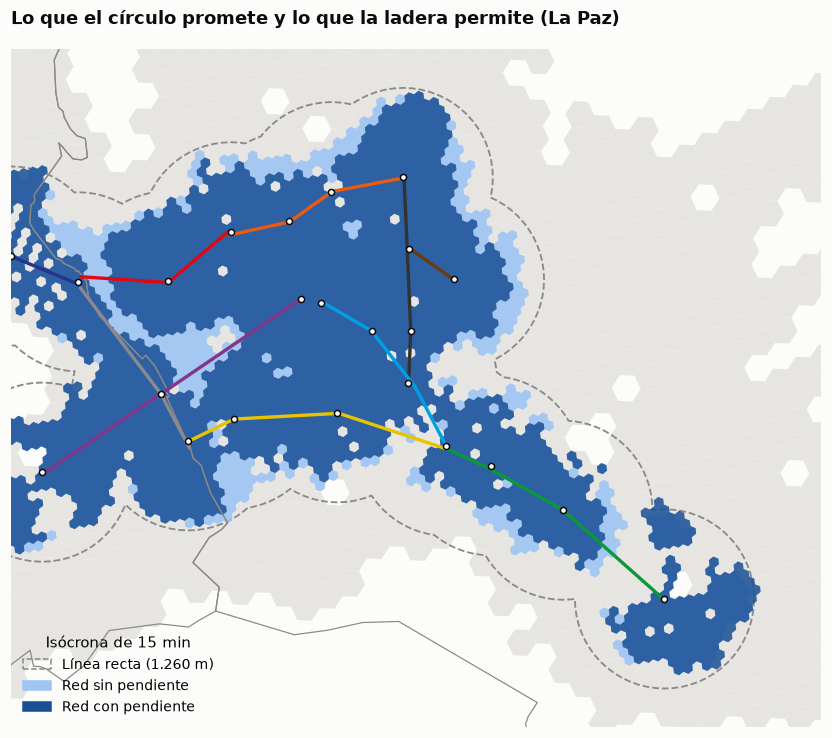

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
zoom = est.query("municipio == 'La Paz'").total_bounds + np.array([-2200, -1800, 2200, 1800])
circ = gpd.GeoSeries(est.buffer(15 * 60 * ac.V_PLANA_MS).union_all(), crs=CRS_METRIC)
hx.plot(ax=ax, color=viz.GRILLA, linewidth=0)
circ.plot(ax=ax, facecolor="none", edgecolor=viz.TINTA_3, lw=1.2, ls="--")
iso.query("escenario == 'plana' and banda_min == 15").plot(ax=ax, color=viz.SECUENCIAL[1], alpha=0.9)
iso.query("escenario == 'pendiente' and banda_min == 15").plot(ax=ax, color=viz.SECUENCIAL[5], alpha=0.85)
viz.mapa_base(ax, mun, lineas, est, zoom)
ax.legend(handles=[Patch(facecolor="none", edgecolor=viz.TINTA_3, ls="--", label="Línea recta (1.260 m)"),
                   Patch(color=viz.SECUENCIAL[1], label="Red sin pendiente"),
                   Patch(color=viz.SECUENCIAL[5], label="Red con pendiente")],
          loc="lower left", fontsize=9, title="Isócrona de 15 min")
ax.set_title("Lo que el círculo promete y lo que la ladera permite (La Paz)")
viz.guardar(fig, "03_isocronas_la_paz")
plt.show()

**Lectura (hipótesis 1, confirmada):**
- La línea recta dice que el 38,5 % vive a ≤ 15 min; con la red y la pendiente es el 24,9 %. **El buffer
  euclidiano sobreestima la cobertura en ~221 mil personas (+54 % relativo).**
- De esa diferencia, ~143 mil personas se deben a la forma de la red (rodeos, quebradas, autopistas sin
  cruce) y **~78 mil a la pendiente**.
- La pendiente pesa **solo en La Paz**: baja la cobertura de 49,5 % a 39,1 % (−10,4 pp, 78 mil personas).
  En El Alto la diferencia es de 401 personas. Es lo que predecía la hipótesis 1: el efecto se concentra
  en las laderas.

### Robustez: ¿depende el resultado de cómo se mide la pendiente?

En el notebook 02, el sobrecosto de la red varía entre 12 % y 33 % según el tratamiento del DSM. Se
recalcula la cobertura con las variantes extremas:

In [7]:
nod = ac.nodos()
a = ac.aristas_tiempo()
mz = ac.manzanos_centroides()
variantes = {"Pendiente neta (sin perfil)": a["t_neta_s"], "Perfil 30 m, σ = 1 (referencia)": a["t_pendiente_s"]}
sigma0 = ac.SIGMA_SUAVIZADO_PX
try:
    ac.SIGMA_SUAVIZADO_PX = 0.0
    variantes["Perfil 15 m, sin suavizar (cota alta)"] = ac.perfil_aristas(a, paso_m=15)["t_pendiente_s"]
finally:
    ac.SIGMA_SUAVIZADO_PX = sigma0

filas = []
for nombre, t in variantes.items():
    T = ac.tiempos_por_estacion(a.assign(t_pendiente_s=t), nod, est)
    r, _ = ac.acceso_manzanos(mz, nod, est, {"pendiente": T["pendiente"]})
    r = r.merge(acc[["codigo", "t_plana_min"]], on="codigo")  # el euclidiano ya viene en r
    c = ac.cobertura(r, "municipio").query("escenario == 'pendiente'").set_index("grupo")["pct_15"]
    filas.append({"variante": nombre, "Total": ac.cobertura(r).set_index("escenario").loc["pendiente", "pct_15"],
                  **c.to_dict()})
pd.DataFrame(filas).set_index("variante")

,Total,El Alto,La Paz
variante,,,
Pendiente neta (sin perfil),25.8,12.7,41.3
"Perfil 30 m, σ = 1 (referencia)",24.9,12.9,39.1
"Perfil 15 m, sin suavizar (cota alta)",20.4,11.2,31.2


**Lectura:** el círculo de 15 minutos alrededor de las estaciones de La Paz cubre casi todo el valle
central, pero la isócrona real queda recortada en las laderas: al norte de las líneas Roja y Naranja, al
oeste de la Morada y a ambos lados de la Verde. Las franjas celestes son lo que la pendiente le quita a la
caminata plana. Están justo en los bordes que suben.

## 4. Ir no es lo mismo que volver

El tiempo de la casa a la estación (ida) y de la estación a la casa (vuelta) difiere cuando hay pendiente.

In [8]:
ida_vuelta = acc.assign(
    ida=(acc["t_pendiente_min"] <= 15) * acc["personas"],
    vuelta=(acc["t_pendiente_salida_min"] <= 15) * acc["personas"],
).groupby("zona")[["personas", "ida", "vuelta"]].sum()
ida_vuelta = ida_vuelta[ida_vuelta["personas"] > 20_000]
ida_vuelta["% ida ≤ 15"] = ida_vuelta["ida"] / ida_vuelta["personas"] * 100
ida_vuelta["% vuelta ≤ 15"] = ida_vuelta["vuelta"] / ida_vuelta["personas"] * 100
ida_vuelta["diferencia (pp)"] = ida_vuelta["% vuelta ≤ 15"] - ida_vuelta["% ida ≤ 15"]
ida_vuelta.sort_values("diferencia (pp)")[["% ida ≤ 15", "% vuelta ≤ 15", "diferencia (pp)"]]

,% ida ≤ 15,% vuelta ≤ 15,diferencia (pp)
zona,,,
Max Paredes,46.0,40.3,-5.7
Periférica,32.3,27.2,-5.1
San Antonio,25.2,20.3,-4.9
Cotahuma,59.3,58.6,-0.7
Centro,95.3,95.2,-0.0
El Alto,12.9,12.9,-0.0
Sur,18.9,19.3,0.4


**Lectura:** con cualquier tratamiento del DEM, la cobertura total queda entre **20 % y 26 %**, y la de La
Paz entre 31 % y 41 %. Siempre está muy por debajo de la red plana (49,5 %) y del buffer euclidiano
(62,4 %). **La conclusión de la hipótesis 1 no depende de la elección del perfil.** La referencia (perfil
cada 30 m, σ = 1) queda en la parte conservadora del rango: si algo, sobreestima la cobertura.

## 5. Por macrodistrito (La Paz) y El Alto

OSM solo tiene los 7 macrodistritos urbanos de La Paz. Para El Alto (14 distritos, solo 3 en OSM) se usa
el municipio completo y el mapa de hexágonos.

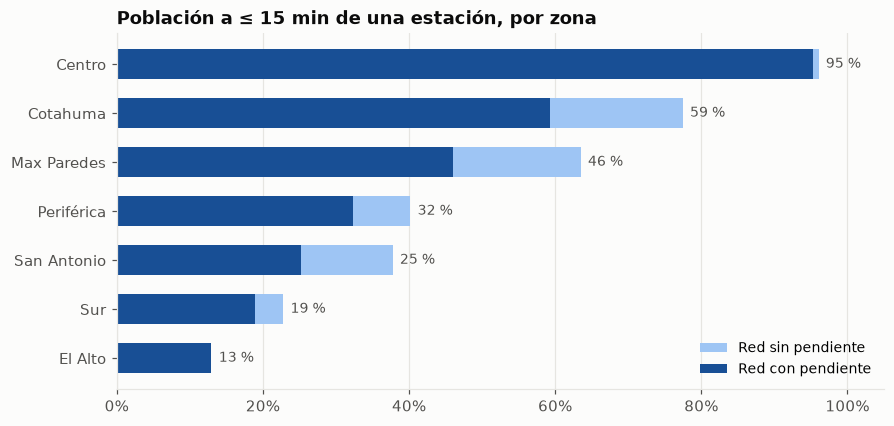

escenario,euclidiano,plana,pendiente,poblacion,no_cubierta,mediana_min
grupo,,,,,,
El Alto,18.2,13.0,12.9,885.210,770.780,49.4
Sur,36.7,22.8,18.9,168.094,136.274,31.0
San Antonio,59.8,37.8,25.2,110.261,82.469,24.3
Periférica,52.1,40.2,32.3,142.143,96.252,23.6
Max Paredes,77.7,63.5,46.0,117.233,63.279,15.8
Cotahuma,87.0,77.5,59.3,140.913,57.326,13.0
Centro,100.0,96.0,95.3,52.793,2.498,7.3


In [9]:
z = ac.cobertura(acc, "zona")
zp = z.pivot(index="grupo", columns="escenario", values="pct_15")[list(ESC)]
zp["poblacion"] = z.drop_duplicates("grupo").set_index("grupo")["poblacion"]
zp = zp[zp["poblacion"] > 15_000].sort_values("pendiente")
zp["no_cubierta"] = zp["poblacion"] * (100 - zp["pendiente"]) / 100
med = acc.groupby("zona").apply(lambda g: ac.mediana_ponderada(g["t_pendiente_min"].clip(upper=60), g["personas"]),
                                include_groups=False)
zp["mediana_min"] = med

fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(zp))
ax.barh(y, zp["plana"], color=viz.SECUENCIAL[1], height=0.6, label="Red sin pendiente")
ax.barh(y, zp["pendiente"], color=viz.SECUENCIAL[5], height=0.6, label="Red con pendiente")
for yy, (p_, pl) in enumerate(zip(zp["pendiente"], zp["plana"])):
    ax.text(max(p_, pl) + 1, yy, f"{p_:.0f} %", va="center", fontsize=9, color=viz.TINTA_2)
ax.set_yticks(y, zp.index)
ax.set_xlim(0, 105)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=9)
ax.set_title("Población a ≤ 15 min de una estación, por zona")
viz.guardar(fig, "03_zonas")
plt.show()
zp.style.format("{:.1f}").format(viz.fmt_int, subset=["poblacion", "no_cubierta"])

**Lectura:** en Max Paredes, Periférica y San Antonio, **volver a casa** desde la estación es más difícil
que ir: la cobertura de vuelta es 5-6 pp menor, porque las estaciones están abajo y las viviendas en la
ladera. Bajar al cable es fácil; subir de regreso, no. En El Alto y el Centro no hay diferencia; en la
zona Sur, la vuelta es apenas más fácil.

## 6. ¿Dónde vive la población no cubierta?

Densidad de los hexágonos donde vive la población a más de 15 minutos (insumo para las zonas sin cobertura del notebook 05).

In [10]:
hx["cubierto"] = hx["t_pendiente_min"] <= 15
hx["no_cub_personas"] = hx["personas"] * (100 - hx["pct_cub_pendiente"]) / 100
dens = hx.assign(denso=hx["densidad_hab_km2"] >= np.percentile(hx["densidad_hab_km2"], 50))
r = dens.groupby(["municipio", "denso"])["no_cub_personas"].sum().unstack()
r.columns = ["hexágonos menos densos", "hexágonos densos (≥ p50)"]
r.loc["Total"] = r.sum()
r.round(0)

,hexágonos menos densos,hexágonos densos (≥ p50)
municipio,,
El Alto,"135,129.0","635,109.0"
La Paz,"73,661.0","383,767.0"
Total,"208,790.0","1,018,876.0"


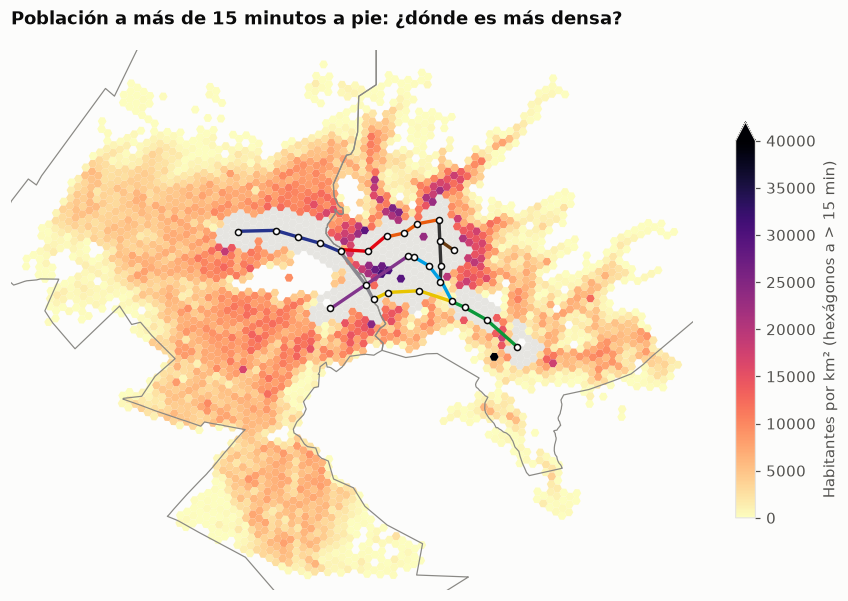

In [11]:
lejos = hx[~hx["cubierto"]]
fig, ax = plt.subplots(figsize=(10, 8.5))
hx[hx["cubierto"]].plot(ax=ax, color=viz.GRILLA, linewidth=0)
lejos.plot(ax=ax, column="densidad_hab_km2", cmap="magma_r", vmin=0, vmax=40_000, linewidth=0, legend=True,
           legend_kwds={"shrink": 0.55, "label": "Habitantes por km² (hexágonos a > 15 min)"})
viz.mapa_base(ax, mun, lineas, est, bounds)
ax.set_title("Población a más de 15 minutos a pie: ¿dónde es más densa?")
viz.guardar(fig, "03_no_cubiertos_densidad")
plt.show()

**Lectura:**
- Ranking de cobertura a ≤ 15 min: Centro (95 %) → Cotahuma (59 %) → Max Paredes (46 %) → Periférica
  (32 %) → San Antonio (25 %) → Sur (19 %) → **El Alto (13 %)**.
- La pendiente le quita más puntos a **Cotahuma y Max Paredes** (−17 a −18 pp frente a la red plana). En
  términos relativos, **San Antonio** pierde un tercio de su cobertura (de 38 % a 25 %).
- En números absolutos, las mayores poblaciones no cubiertas son **El Alto (771 mil, mediana de 49
  min)**, la **zona Sur (136 mil)** y Periférica (96 mil).

**Lectura:**
- La población no cubierta no está dispersa: **~1,02 M de las 1,23 M personas a más de 15 minutos viven en
  la mitad más densa de los hexágonos** (635 mil en El Alto y 384 mil en La Paz).
- Los hexágonos no cubiertos **más densos** (20-30 mil hab/km²) están en las laderas de La Paz, justo en
  el borde de las isócronas (norte de las líneas Roja y Naranja, alrededor de la Morada). Son los
  candidatos naturales para **estaciones adicionales en líneas existentes**.
- En El Alto la densidad es menor (8-15 mil hab/km²), pero la mancha es enorme y continua al norte y al
  sur del corredor. Ahí cabe una **línea nueva**. Las zonas sin cobertura se delimitan con DBSCAN en el notebook 05.

## 7. Captación de cada estación frente a su demanda (anticipo del notebook 04)

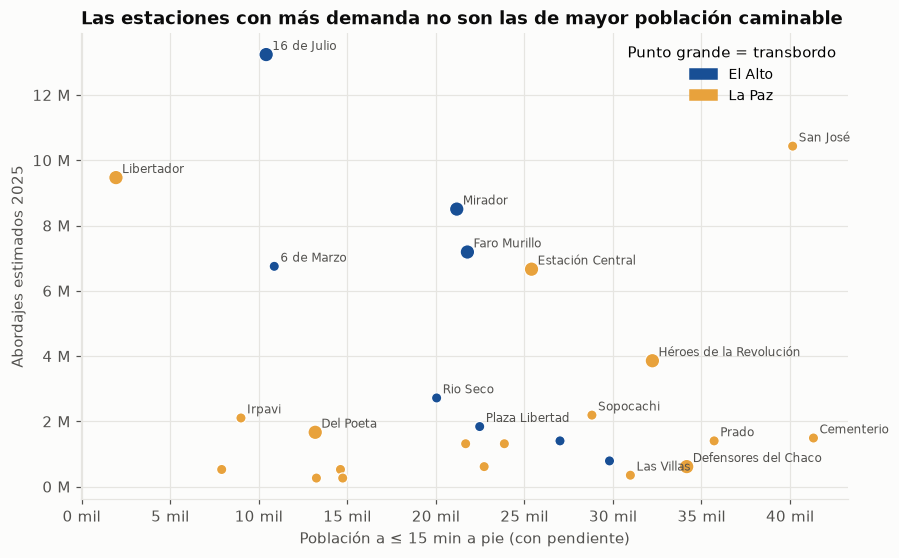

Correlación de Spearman con los abordajes 2025:
  pob_pendiente_10     -0.12
  pob_pendiente_15     -0.08
  pob_pendiente_20     -0.07
  pob_plana_15         -0.11
  pob_buffer_500m      -0.13


,municipio,lineas,pasajeros_est,pob_pendiente_10,pob_pendiente_15,pob_exclusiva_pendiente_15,pasajeros_por_hab_15
nombre,,,,,,,
16 de Julio,El Alto,"Azul, Plateada, Roja",13.238.503,4.506,10.423,5.867,"1,270"
San José,La Paz,Morada,10.432.993,17.577,40.150,27.276,260
Libertador,La Paz,"Amarilla, Celeste, Verde",9.468.598,182,1.942,1.336,"4,876"
Mirador,El Alto,"Amarilla, Plateada",8.504.204,9.476,21.185,15.383,401
Faro Murillo,El Alto,"Morada, Plateada",7.189.121,8.939,21.785,15.321,330
6 de Marzo,El Alto,Morada,6.750.760,3.811,10.880,10.461,620
Estación Central,La Paz,"Naranja, Roja",6.663.088,8.007,25.406,15.487,262
Héroes de la Revolución,La Paz,"Blanca, Naranja",3.857.577,12.676,32.230,26.161,120
Rio Seco,El Alto,Azul,2.717.838,5.814,20.048,19.449,136


In [12]:
dem = demanda.estaciones_fisicas(demanda.cargar())
ce = cap.merge(dem[["slug", "pasajeros_est", "lineas", "transbordo"]], on="slug")
ce["pasajeros_por_hab_15"] = ce["pasajeros_est"] / ce["pob_pendiente_15"]

fig, ax = plt.subplots(figsize=(9, 5.5))
col = ce["municipio"].map({"El Alto": viz.SECUENCIAL[5], "La Paz": "#e8a23c"})
ax.scatter(ce["pob_pendiente_15"], ce["pasajeros_est"], c=col, s=np.where(ce["transbordo"], 90, 45),
           edgecolor="white", lw=0.8, zorder=3)
for r_ in ce[(ce["pasajeros_est"] > 1.6e6) | (ce["pob_pendiente_15"] > 30_000)].itertuples():
    ax.annotate(r_.nombre, (r_.pob_pendiente_15, r_.pasajeros_est), xytext=(4, 3), textcoords="offset points",
                fontsize=8, color=viz.TINTA_2)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(viz.miles))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(viz.millones))
ax.set_xlabel("Población a ≤ 15 min a pie (con pendiente)")
ax.set_ylabel("Abordajes estimados 2025")
ax.legend(handles=[Patch(color=viz.SECUENCIAL[5], label="El Alto"), Patch(color="#e8a23c", label="La Paz")],
          loc="upper right", fontsize=9, title="Punto grande = transbordo")
ax.set_title("Las estaciones con más demanda no son las de mayor población caminable")
viz.guardar(fig, "03_captacion_vs_demanda")
plt.show()
rho = ce[["pob_pendiente_10", "pob_pendiente_15", "pob_pendiente_20", "pob_plana_15", f"pob_buffer_{ac.BUFFER_CLASICO_M}m"]].corrwith(
    ce["pasajeros_est"], method="spearman")
print("Correlación de Spearman con los abordajes 2025:")
for k, v in rho.items():
    print(f"  {k:<20} {v:+.2f}")
ce.sort_values("pasajeros_est", ascending=False)[
    ["nombre", "municipio", "lineas", "pasajeros_est", "pob_pendiente_10", "pob_pendiente_15",
     "pob_exclusiva_pendiente_15", "pasajeros_por_hab_15"]].set_index("nombre").style.format(
    {"pasajeros_est": viz.fmt_int, "pob_pendiente_10": viz.fmt_int, "pob_pendiente_15": viz.fmt_int,
     "pob_exclusiva_pendiente_15": viz.fmt_int, "pasajeros_por_hab_15": "{:,.0f}"})

**Lectura:**
- **La población caminable no explica la demanda de una estación** (Spearman ≈ −0,1). Las estaciones con
  más abordajes son **cabeceras y transbordos**: 16 de Julio (13,2 M con solo ~10 mil vecinos a pie),
  Libertador (9,5 M con ~2 mil), Mirador, Faro Murillo. Su captación real llega en **minibús** y desde
  otras líneas.
- Las estaciones residenciales del valle (Cementerio, Prado, Las Villas, Defensores del Chaco) tienen
  30-40 mil vecinos a pie, pero pocos abordajes: la gente que vive cerca del centro tiene alternativas o
  no necesita el cable para sus viajes.
- **Implicación para el notebook 04:** el modelo de demanda necesita variables de red (transbordo,
  cabecera, conexión con El Alto) además de la población caminable. Con n = 26, la población a pie sola
  sirve de poco.

## 8. Lente de equidad: ¿quién queda lejos?

Índice de vulnerabilidad (IV) por manzano con 7 carencias de la ficha censal: sin educación superior,
sin seguro de salud, sin agua por red, sin alcantarillado, sin internet, hacinamiento alto y piso de
tierra. El IV es el promedio de los rangos percentiles ponderados por población (0 a 1); los quintiles
dividen a la población en cinco grupos del mismo tamaño. Cubre el 96 % de la población.

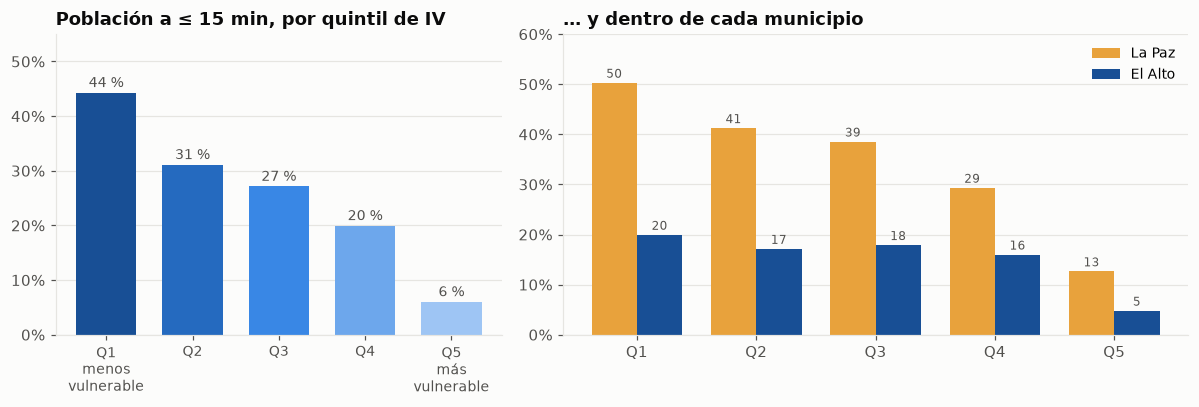

Composición de cada municipio por quintil de IV (% de su población):


,poblacion,pct_cubierta_15min,t_medio_min,% pob. El Alto,% pob. La Paz
iv_quintil,,,,,
Q1 (menos vulnerable),314027,44.3,23.9,7.3,35.0
Q2,314143,31.1,28.9,15.5,25.3
Q3,314053,27.2,31.6,20.4,19.6
Q4,314073,20.0,36.3,25.9,13.0
Q5 (más vulnerable),314102,6.0,48.1,31.0,7.0


In [13]:
qt = eqm.cobertura_por_quintil(eq)
qm = eqm.cobertura_por_quintil(eq, por="municipio")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axs[0]
ax.bar(range(5), qt["pct_cubierta_15min"], color=viz.SECUENCIAL[1:6][::-1], width=0.7)
for i, v in enumerate(qt["pct_cubierta_15min"]):
    ax.text(i, v + 1, f"{v:.0f} %", ha="center", fontsize=9, color=viz.TINTA_2)
ax.set_xticks(range(5), ["Q1\nmenos\nvulnerable", "Q2", "Q3", "Q4", "Q5\nmás\nvulnerable"], fontsize=9)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, 55)
ax.grid(axis="x", visible=False)
ax.set_title("Población a ≤ 15 min, por quintil de IV")

ax = axs[1]
w = 0.38
for j, (m, c) in enumerate([("La Paz", "#e8a23c"), ("El Alto", viz.SECUENCIAL[5])]):
    vals = qm.loc[m, "pct_cubierta_15min"]
    ax.bar(np.arange(5) + (j - 0.5) * w, vals, width=w, color=c, label=m)
    for i, v in enumerate(vals):
        ax.text(i + (j - 0.5) * w, v + 1, f"{v:.0f}", ha="center", fontsize=8, color=viz.TINTA_2)
ax.set_xticks(range(5), ["Q1", "Q2", "Q3", "Q4", "Q5"])
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, 60)
ax.grid(axis="x", visible=False)
ax.legend(fontsize=9)
ax.set_title("… y dentro de cada municipio")
fig.tight_layout()
viz.guardar(fig, "03_equidad_quintiles")
plt.show()

composicion = (qm["poblacion"].unstack(0) / qm["poblacion"].unstack(0).sum() * 100).round(1)
print("Composición de cada municipio por quintil de IV (% de su población):")
pd.concat([qt.round(1), composicion.add_prefix("% pob. ")], axis=1)

In [14]:
print("Correlación de Spearman entre cada carencia y el tiempo a la estación (por manzano):")
eqm.correlaciones(eq).rename(index={k: v[0] for k, v in eqm.INDICADORES.items()} | {"iv": "Índice de vulnerabilidad"})

Correlación de Spearman entre cada carencia y el tiempo a la estación (por manzano):


19+ años sin educación superior         0.5
Sin seguro de salud                    -0.1
Vivienda sin agua por cañería de red    0.2
Vivienda sin alcantarillado             0.5
Hogar sin internet                      0.2
Vivienda con hacinamiento alto          0.1
Vivienda con piso de tierra             0.3
Índice de vulnerabilidad                0.4
dtype: float64

### Brecha de accesibilidad: vulnerabilidad × falta de acceso

`brecha = IV × falta de acceso`, con la falta de acceso en 0 a ≤ 10 min y en 1 a ≥ 30 min. Un hexágono
con brecha alta tiene a la vez población vulnerable y lejana.

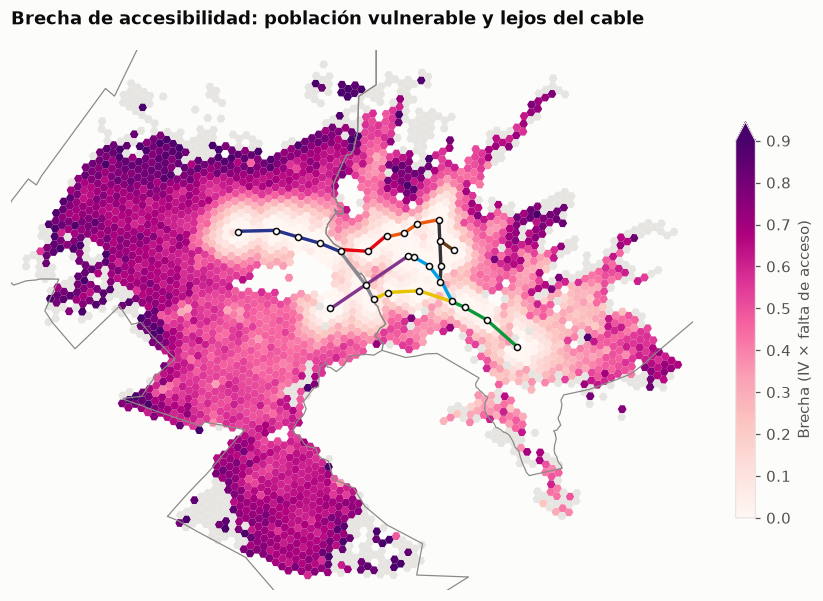

,personas,pob_brecha_alta,brecha_media,"% pob. en brecha alta (≥ 0,6)"
zona,,,,
El Alto,879.364,314.632,0.48,35.8 %
Periférica,144.066,9.426,0.28,6.5 %
Sur,167.377,7.971,0.28,4.8 %
La Paz (otros),10.689,6.406,0.56,59.9 %
Max Paredes,118.271,4.219,0.20,3.6 %
San Antonio,110.812,3.776,0.27,3.4 %
Mallasa,9.236,1.180,0.40,12.8 %
Cotahuma,145.555,358,0.14,0.2 %
Centro,50.065,0,0.01,0.0 %


In [15]:
bh = hx.merge(eqm.por_h3(eq), on="h3", how="left")
fig, ax = plt.subplots(figsize=(10, 8.5))
bh.plot(ax=ax, column="brecha", cmap="RdPu", vmin=0, vmax=0.9, linewidth=0, legend=True,
        missing_kwds={"color": viz.GRILLA}, legend_kwds={"shrink": 0.55, "label": "Brecha (IV × falta de acceso)"})
viz.mapa_base(ax, mun, lineas, est, bounds)
ax.set_title("Brecha de accesibilidad: población vulnerable y lejos del cable")
viz.guardar(fig, "03_brecha")
plt.show()

bh["personas_brecha"] = bh["personas"] * bh["brecha"].fillna(0)
bh["pob_brecha_alta"] = bh["personas"] * (bh["brecha"] >= 0.6)
top = bh.groupby("zona")[["personas", "pob_brecha_alta", "personas_brecha"]].sum()
top["brecha_media"] = top.pop("personas_brecha") / top["personas"]
top["% pob. en brecha alta (≥ 0,6)"] = top["pob_brecha_alta"] / top["personas"] * 100
top.sort_values("pob_brecha_alta", ascending=False).style.format(
    {"personas": viz.fmt_int, "pob_brecha_alta": viz.fmt_int, "brecha_media": "{:.2f}",
     "% pob. en brecha alta (≥ 0,6)": "{:.1f} %"})

**Lectura:**
- **La cobertura cae a lo largo del gradiente de vulnerabilidad: del 44 % en el quintil menos vulnerable
  al 6 % en el más vulnerable** (tiempo medio de 24 a 48 minutos).
- No es solo un efecto "El Alto frente a La Paz": **dentro de cada municipio** el quintil más vulnerable
  es el peor cubierto (El Alto: 20 % en Q1 frente a 5 % en Q5; La Paz: 50 % frente a 13 %).
- El Alto concentra la vulnerabilidad: el 31 % de su población está en Q5, frente al 7 % de La Paz.
- Las carencias más asociadas a vivir lejos del cable son la **falta de educación superior y de
  alcantarillado** (ρ ≈ 0,5): las periferias urbanas más nuevas y menos consolidadas.
- **~546 mil personas de los quintiles 4 y 5 viven a más de 15 minutos** de una estación.
- La brecha alta (≥ 0,6) se concentra en **El Alto: 315 mil personas (36 % de su población)**, sobre todo
  en el norte, el oeste y el sur. En La Paz aparece en las laderas altas de Periférica y en la zona Sur.

## 9. Conclusiones

| # | Hallazgo | Implicación |
|---|---|---|
| 1 | Solo el **24,9 %** de la población (~408 mil) vive a ≤ 15 min a pie de una estación; **1,23 M** quedan afuera. Mediana: 31 min | El cable sirve a un corredor angosto. La mayoría llega en minibús o no lo usa |
| 2 | **El Alto: 12,9 %** cubierto frente a La Paz: 39,1 %. 771 mil alteños a más de 15 min | La expansión debe priorizar **El Alto** (coincide con el notebook 01) |
| 3 | **H1 confirmada:** el buffer euclidiano dice 38,5 %; la red con pendiente, 24,9 % (sobreestimación de ~221 mil personas, +54 %). La pendiente sola quita 78 mil personas, todas en La Paz | Los estudios con buffers inflan la cobertura. La pendiente es indispensable en las laderas, irrelevante en el altiplano |
| 4 | El resultado es robusto al tratamiento del DSM (cobertura total entre 20 y 26 %) | Se mantiene el perfil cada 30 m con σ = 1 como referencia |
| 5 | En las laderas, la cobertura de vuelta (estación → casa) es 5-6 pp menor que la de ida | Las estaciones en el fondo del valle sirven peor a quien vive arriba |
| 6 | 1,02 M de no cubiertos viven en la mitad más densa de los hexágonos. Los más densos están en los bordes de las laderas de La Paz y en la gran mancha alteña | Dos estrategias: **estaciones intermedias** en laderas paceñas y **línea nueva** en El Alto (notebook 05) |
| 7 | La población caminable no explica los abordajes por estación (ρ ≈ −0,1). Mandan las cabeceras y los transbordos | El modelo de demanda (notebook 04) debe incluir variables de red y de alimentación |
| 8 | Cobertura del 44 % (Q1) frente al 6 % (Q5) de vulnerabilidad, también dentro de cada municipio. ~546 mil personas vulnerables (Q4-Q5) sin acceso a pie | La nueva línea tiene un argumento de **equidad**, además del de demanda |

**Siguiente paso:** modelo de demanda por estación (notebook 04) y zonas sin cobertura y optimización
de nuevas estaciones (notebook 05), ponderando la demanda por la población no cubierta y la brecha.

## Anexo: exportación de datos para el sitio

In [16]:
from teleferico.export_web import exportar_accesibilidad
exportar_accesibilidad(acc, eq)